# FL-ATTACK-003.2 — Byzantine attacks (random, sign-flip, scale, drift)

*Epic EPIC-001 · story fl_attack_003 · all results below are loaded from files produced by the task's experiment function and labelled MEASURED/SIMULATED; clients are virtual; data is synthetic.*

## 1. Research objective
Quantify accuracy damage of Byzantine updates and the effect of robust aggregators.

## 2. Scientific background
Median, trimmed mean and Krum offer Byzantine robustness under assumptions on the malicious fraction [blanchard2017, yin2018, fang2020].

References use keys of `docs/references/references_master.md` (status per entry).

## 3. Research questions
- **RQ1.** Which aggregator preserves accuracy under which behaviour and fraction?
- **RQ2.** What is the clean-run cost of robustness?

## 4. Hypotheses
- **H1.** Mean aggregation degrades under sign-flip; robust rules do not.

## 5. Mathematical formulation
Krum score s_i = Σ_{j∈N_i} ||Δ_i−Δ_j||², n ≥ 2f+3; median per coordinate; trimmed mean removes β fraction each side.

## 6. Experimental environment

In [1]:
import os, sys, json, platform, warnings
from pathlib import Path
warnings.filterwarnings("ignore")
os.environ.setdefault("MLFLOW_DISABLE_AGENT_HINT", "1")
def _find_root():
    p = Path(os.environ.get("FL_ROOT") or os.environ.get("RS_ROOT") or Path.cwd()).resolve()
    for q in [p, *p.parents]:
        if (q / "src" / "federated_learning").exists():
            return q
    raise RuntimeError("repository root not found; set RS_ROOT")
ROOT = _find_root()
sys.path.insert(0, str(ROOT / "src"))
STORY = "fl_attack_003"
_cands = [ROOT / "experiments" / "results" / STORY]
RES = next(c for c in _cands if c.exists())
import numpy as np, pandas as pd
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt
from IPython.display import Image, display
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
SEED = 0; np.random.seed(SEED)
def show_csv(name, n=12):
    p = RES / name
    if p.exists(): display(pd.read_csv(p).round(4).head(n))
    else: print("MISSING", name)
def show_fig(name):
    for base in (RES / "figures", RES):
        if (base / name).exists(): display(Image(filename=str(base / name))); return
    print("MISSING figure", name)
print("root:", ROOT, "| results:", RES)

root: /home/claude/fl_sprint | results: /home/claude/fl_sprint/experiments/results/fl_attack_003


In [2]:
import importlib.metadata as md
vers = {}
for p in ["numpy","scipy","scikit-learn","torch","tenseal","phe","pandas","matplotlib","cryptography","psutil","mlflow","opacus"]:
    try: vers[p] = md.version(p)
    except Exception: vers[p] = "not installed"
print(json.dumps(dict(python=platform.python_version(), platform=platform.platform(), versions=vers, seed=SEED, gpu="none (CPU only; GPU metrics NOT_MEASURED)"), indent=1))

{
 "python": "3.13.18",
 "platform": "Linux-6.18.44-fc-v338-x86_64-with-glibc2.39",
 "versions": {
  "numpy": "2.5.3",
  "scipy": "1.18.1",
  "scikit-learn": "1.9.1",
  "torch": "2.15.0",
  "tenseal": "0.3.18",
  "phe": "1.5.0",
  "pandas": "3.0.5",
  "matplotlib": "3.11.2",
  "cryptography": "50.0.1",
  "psutil": "7.2.2",
  "mlflow": "3.18.0",
  "opacus": "1.6.0"
 },
 "seed": 0,
 "gpu": "none (CPU only; GPU metrics NOT_MEASURED)"
}


## 7. Dataset description
Synthetic binary tabular dataset **SYN-IDS-v1** (scikit-learn `make_classification`, 40 features, 70:30 split). Chosen because no real IDS/clinical dataset was available in the sandbox. It has no clinical meaning; conclusions about absolute accuracy do not transfer.

In [3]:
from federated_learning.synthetic_data.generators.syn_ids_v1 import make_dataset, DATASET_ID
from federated_learning.data_partitioning.iid import partition_iid
from federated_learning.data_partitioning.dirichlet import partition_dirichlet
from federated_learning.data_partitioning.metrics import label_skew_stat
data = make_dataset(n_samples=6000, seed=SEED)
print(DATASET_ID, "train", data.X_train.shape, "test", data.X_test.shape, "positive rate", float(data.y_train.mean()))
print("NOTE: SYNTHETIC tabular data (not CIC-IDS-2017, not patient data); clients are VIRTUAL, not hospitals.")

SYN-IDS-v1 train (4200, 40) test (1800, 40) positive rate 0.40095238095238095
NOTE: SYNTHETIC tabular data (not CIC-IDS-2017, not patient data); clients are VIRTUAL, not hospitals.


## 8. Configuration and reproducibility settings
Seeds are fixed; each stored result carries `provenance` (experiment id, SHA-256 of the configuration, environment versions; `git_commit` is `null` because the workspace is not a git repository).

In [4]:
from federated_learning.training.config import FLConfig
cfg = FLConfig(rounds=5, local_epochs=1, seed=SEED)
print(cfg)

FLConfig(algo='fedavg', rounds=5, local_epochs=1, lr=0.05, batch_size=32, participation=1.0, mu=0.0, hidden=32, act='relu', seed=0, hetero_epochs=False, eval_every=1, server_lr=1.0)


## 9. Data preparation
Partitioning into virtual clients (IID or Dirichlet label skew) is performed by `federated_learning.data_partitioning`.

In [5]:
parts_iid = partition_iid(data.y_train, 10, SEED)
parts_dir = partition_dirichlet(data.y_train, 10, 0.3, SEED)
print('label-skew statistic IID:', round(label_skew_stat(data.y_train, parts_iid),3), ' Dirichlet(0.3):', round(label_skew_stat(data.y_train, parts_dir),3))

label-skew statistic IID: 0.019  Dirichlet(0.3): 0.363


## 10. Implementation
Reusable code lives in `src/federated_learning/` (`attacks.py`, `defenses.py`, `fl.py`). The cell below exercises it live (small, fast, deterministic) and asserts correctness.

In [6]:
from federated_learning.aggregators.mean import WeightedMean
from federated_learning.aggregators.robust import CoordinateMedian, TrimmedMean, Krum
from federated_learning.aggregators.defenses import ClippedMean
r = np.random.default_rng(SEED); D = r.normal(1.0, .05, (10, 30)).astype(np.float32); D[:2] = -50.0; W = np.ones(10)
for a in (WeightedMean(), CoordinateMedian(), TrimmedMean(0.25), Krum(2, 1)):
    print(f"{type(a).__name__:18s} max|agg-1| = {np.abs(a.aggregate(D, W) - 1.0).max():.3f}")

WeightedMean       max|agg-1| = 10.245
CoordinateMedian   max|agg-1| = 0.067
TrimmedMean        max|agg-1| = 0.077
Krum               max|agg-1| = 0.128


## 11. Experiment execution
The full experiment was executed by `python -m federated_learning.pipelines.experiments.run_all --task FL-ATTACK-003.2` (see `logs/`). Its raw per-run results are loaded here; they are not re-computed inside the notebook.

In [7]:
show_csv('task_3_2_runs.csv')
show_csv('task_3_2_clean_cost.csv')

,seed,mal_frac,behavior,aggregator,acc,loss,f1,agg_time_ms_per_round,status
0,0,0.0,none,mean,0.7781,0.4705,0.7053,0.2646,ok
1,0,0.0,none,median,0.7767,0.4723,0.7024,1.0545,ok
2,0,0.0,none,trimmed_mean,0.7772,0.4710,0.7036,0.3747,ok
3,0,0.0,none,krum,0.7692,0.4804,0.6966,0.4880,ok
4,0,0.0,none,multi_krum,0.7775,0.4707,0.7034,0.4358,ok
5,0,0.1,random,mean,0.7750,0.4816,0.7002,0.2463,ok
6,0,0.1,sign_flip,mean,0.7081,0.5682,0.5712,0.2662,ok
7,0,0.1,scale,mean,0.7975,0.4286,0.7346,0.2355,ok
8,0,0.1,drift,mean,0.7794,0.4706,0.7068,0.2613,ok
9,0,0.1,random,median,0.7772,0.4750,0.7032,0.9718,ok


,aggregator,clean_acc
0,mean,0.7796
1,median,0.7801
2,trimmed_mean,0.7796
3,krum,0.7717
4,multi_krum,0.7795


## 12. Metrics collection
Metric definitions: MEASURED over seeds: attack metric (ASR / AUC / success rate), clean accuracy, defense cost. Intensity levels low/medium/high are defined in docs/fl_attack_003/attack_methodology.md.

In [8]:
show_csv('task_3_2_summary.csv')

,mal_frac,behavior,aggregator,acc,acc_ci,loss,agg_ms
0,0.1,random,mean,0.7736,"[0.770, 0.777]",0.4773,0.2519
1,0.1,random,median,0.7780,"[0.772, 0.784]",0.4701,0.9828
2,0.1,random,trimmed_mean,0.7778,"[0.771, 0.784]",0.4704,0.4630
3,0.1,random,krum,0.7742,"[0.766, 0.782]",0.4741,0.4947
4,0.1,random,multi_krum,0.7801,"[0.776, 0.784]",0.4665,0.5037
5,0.1,sign_flip,mean,0.7125,"[0.692, 0.733]",0.5669,0.2718
6,0.1,sign_flip,median,0.7738,"[0.768, 0.779]",0.4766,0.9997
7,0.1,sign_flip,trimmed_mean,0.7722,"[0.770, 0.774]",0.4789,0.4136
8,0.1,sign_flip,krum,0.7742,"[0.766, 0.782]",0.4741,0.4975
9,0.1,sign_flip,multi_krum,0.7801,"[0.776, 0.784]",0.4665,0.4699


## 13. Statistical analysis
95% CIs over seeds; AUC/ASR CIs may extend beyond [0,1] because they are t-intervals on few seeds (reported as computed).

In [9]:
show_csv('task_3_2_summary.csv', 30)

,mal_frac,behavior,aggregator,acc,acc_ci,loss,agg_ms
0,0.1,random,mean,0.7736,"[0.770, 0.777]",0.4773,0.2519
1,0.1,random,median,0.7780,"[0.772, 0.784]",0.4701,0.9828
2,0.1,random,trimmed_mean,0.7778,"[0.771, 0.784]",0.4704,0.4630
3,0.1,random,krum,0.7742,"[0.766, 0.782]",0.4741,0.4947
4,0.1,random,multi_krum,0.7801,"[0.776, 0.784]",0.4665,0.5037
5,0.1,sign_flip,mean,0.7125,"[0.692, 0.733]",0.5669,0.2718
6,0.1,sign_flip,median,0.7738,"[0.768, 0.779]",0.4766,0.9997
7,0.1,sign_flip,trimmed_mean,0.7722,"[0.770, 0.774]",0.4789,0.4136
8,0.1,sign_flip,krum,0.7742,"[0.766, 0.782]",0.4741,0.4975
9,0.1,sign_flip,multi_krum,0.7801,"[0.776, 0.784]",0.4665,0.4699


## 14. Visualizations

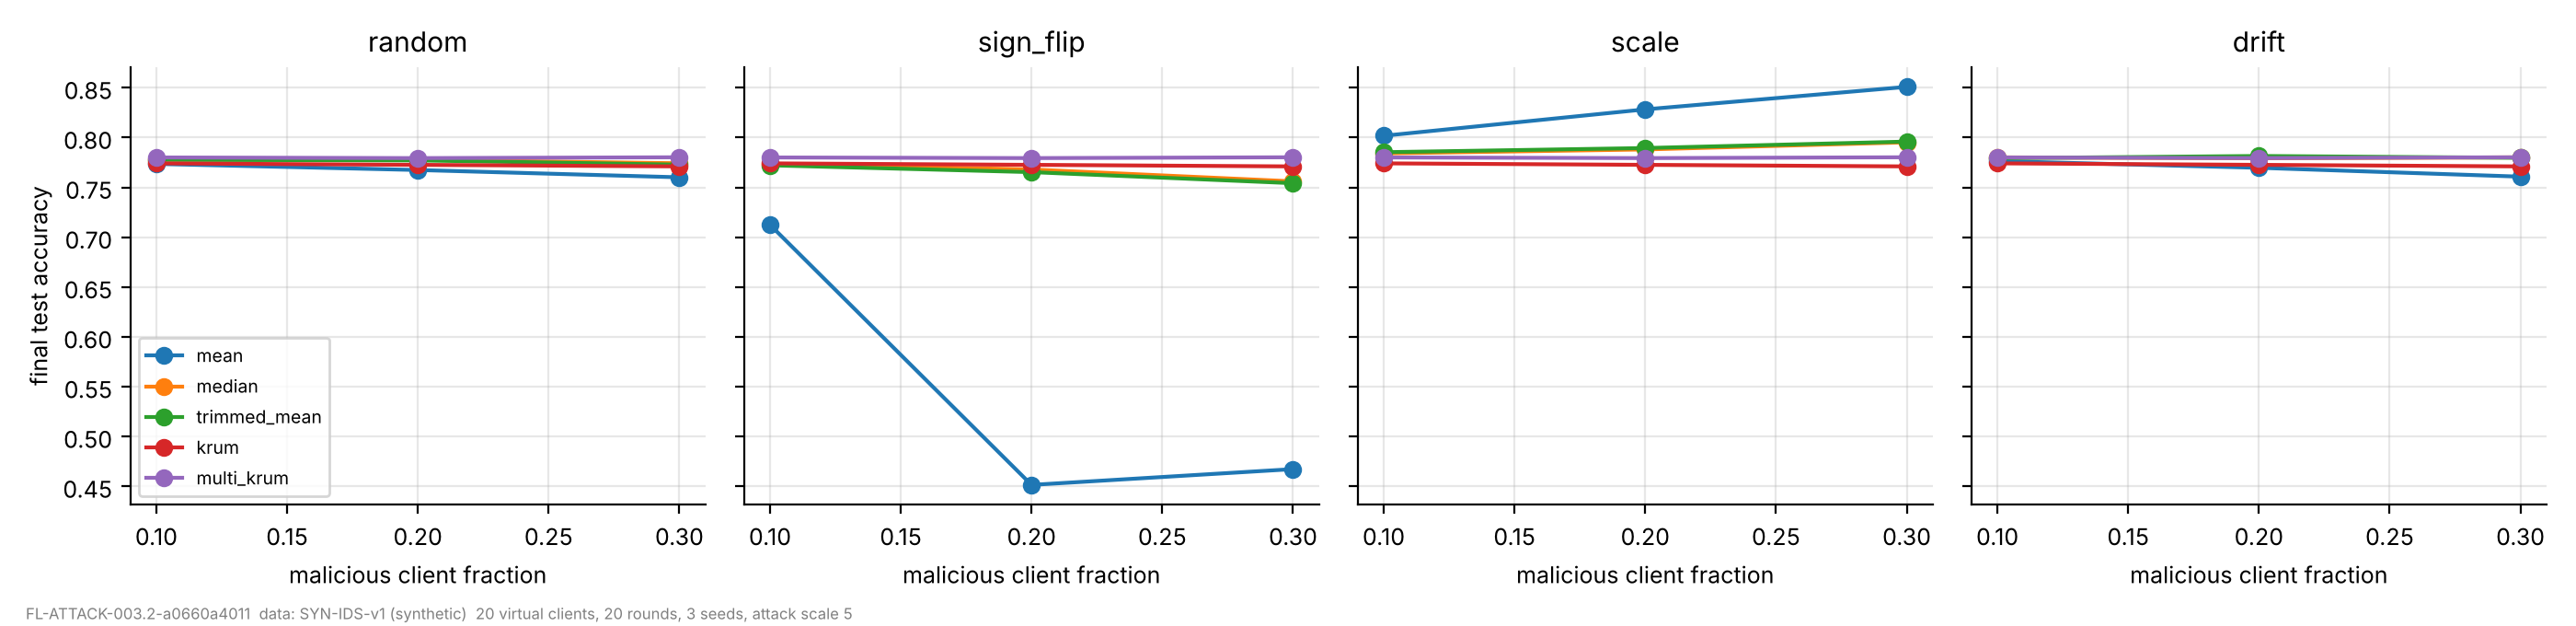

In [10]:
show_fig('task_3_2_byzantine.png')

## 15. Interpretation of results
The numbers are computed in the next cell from the stored data; the text interprets only what that cell prints.

Plain mean is damaged by sign-flip (largest at 30%); robust rules hold. Note: 'scale' under mean can *raise* accuracy (a scaled benign update acts like a larger step) – reported as measured, not as robustness.

In [11]:
d = pd.read_csv(RES / 'task_3_2_summary.csv'); print(d.pivot_table(index=['mal_frac','behavior'], columns='aggregator', values='acc').round(3).to_string())

aggregator           krum   mean  median  multi_krum  trimmed_mean
mal_frac behavior                                                 
0.1      drift      0.774  0.776   0.780       0.780         0.779
         random     0.774  0.774   0.778       0.780         0.778
         scale      0.774  0.802   0.784       0.780         0.785
         sign_flip  0.774  0.712   0.774       0.780         0.772
0.2      drift      0.773  0.770   0.779       0.779         0.782
         random     0.773  0.768   0.778       0.779         0.777
         scale      0.773  0.828   0.788       0.779         0.790
         sign_flip  0.773  0.452   0.768       0.779         0.765
0.3      drift      0.771  0.761   0.780       0.780         0.780
         random     0.771  0.760   0.774       0.780         0.773
         scale      0.771  0.851   0.795       0.780         0.796
         sign_flip  0.771  0.467   0.756       0.780         0.754


## 16. Limitations
- Krum requires n ≥ 2f+3.
- Synthetic data, virtual clients on one machine, 2 CPU cores, no GPU; no real network. Comm. bytes are logical payload sizes.
- No regulatory/compliance conclusion can be drawn from this notebook.

## 17. Conclusions
Robust aggregation preserves accuracy in the tested settings; secure aggregation alone does not provide this.

**Jira acceptance:** see `docs/fl_attack_003/results_and_discussion.md` for the criterion-by-criterion verdict (MET / PARTIALLY MET / NOT MET).

## 18. References
`blanchard2017`, `yin2018`, `fang2020` — details in `docs/fl_attack_003/references.md`.